In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement avec chemins relatifs
df_rte = pd.read_csv("../data/df_rte.csv")
df_meteo = pd.read_csv("../data/df_meteo.csv")

print("=== RTE ===")
print(df_rte.info())
print(df_rte.head(2))

print("\n=== METEO ===")
print(df_meteo.info())
print(df_meteo.head(2))

=== RTE ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210408 entries, 0 to 210407
Data columns (total 9 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   date_heure_utc        210408 non-null  object 
 1   consommation          105203 non-null  float64
 2   solaire               105203 non-null  float64
 3   eolien                105203 non-null  float64
 4   nucleaire             105203 non-null  float64
 5   hydraulique           105203 non-null  float64
 6   gaz                   105203 non-null  float64
 7   ech_physiques         105203 non-null  float64
 8   charge_residuelle_mw  105203 non-null  float64
dtypes: float64(8), object(1)
memory usage: 14.4+ MB
None
              date_heure_utc  consommation  solaire  eolien  nucleaire  \
0  2020-01-01 00:00:00+00:00       63943.0     -1.0  3203.0    48970.0   
1  2020-01-01 00:15:00+00:00           NaN      NaN     NaN        NaN   

   hydraulique     gaz  e

In [ ]:
# 1. Voir quelles sont les villes présentes dans df_meteo
print("Villes dans le dataset météo :", df_meteo["ville"].unique())

# 2. Nettoyage et agrégation de df_rte : moyenne des 2 observations (xx:00 et xx:30) par heure
df_rte_clean = df_rte.dropna(subset=["consommation"]).copy()
df_rte_clean["date_heure_utc"] = pd.to_datetime(df_rte_clean["date_heure_utc"]).dt.floor("h")
df_rte_horaire = (
    df_rte_clean.groupby("date_heure_utc", as_index=False)
    .mean(numeric_only=True)
)

# 3. Agrégation de df_meteo : moyenne nationale par heure (des 3 villes)
df_meteo["date_heure_utc"] = pd.to_datetime(df_meteo["date_heure_utc"])
df_meteo_nat = (
    df_meteo.groupby("date_heure_utc", as_index=False)[
        ["wind_speed_100m", "shortwave_radiation", "temperature_2m"]
    ]
    .mean()
)

# 4. Jointure (merge) des deux tables sur la colonne date_heure_utc
df = pd.merge(df_rte_horaire, df_meteo_nat, on="date_heure_utc", how="inner")

# 5. Petit nettoyage final et création de variables utiles
df["enr_total"] = df["solaire"] + df["eolien"]
df["part_enr"] = (df["enr_total"] / df["consommation"]) * 100

# Vérification du résultat
print(f"Nombre d'heures après fusion : {len(df)}")
print(f"Période couverte : du {df['date_heure_utc'].min()} au {df['date_heure_utc'].max()}")
display(df.head(3))

Villes dans le dataset météo : ['Brest' 'Marseille' 'Paris']
Nombre d'heures après fusion : 52602
Période couverte : du 2020-01-01 00:00:00+00:00 au 2025-12-31 23:00:00+00:00


,date_heure_utc,consommation,solaire,eolien,nucleaire,hydraulique,gaz,ech_physiques,charge_residuelle_mw,wind_speed_100m,shortwave_radiation,temperature_2m,enr_total,part_enr
0,2020-01-01 00:00:00+00:00,63923.5,0.0,3092.0,49309.0,9128.5,5943.5,-4812.5,60832.5,1.380000,0.0,4.900000,3092.0,4.837032
1,2020-01-01 01:00:00+00:00,63059.5,0.0,2781.0,49755.5,8455.5,4916.0,-4107.5,60279.5,1.523333,0.0,4.833333,2781.0,4.410121
2,2020-01-01 02:00:00+00:00,60078.5,0.0,2816.0,49707.0,7496.5,3301.0,-3780.5,57263.5,2.000000,0.0,4.600000,2816.0,4.687201


In [3]:
# TABLEAU DE STATISTIQUES DESCRIPTIVES & CORRÉLATIONS
cols_meteo = ["wind_speed_100m", "shortwave_radiation", "temperature_2m"]
cols_elec = ["consommation", "solaire", "eolien", "enr_total", "nucleaire", "gaz", "charge_residuelle_mw"]

print("=== STATISTIQUES DESCRIPTIVES (MOYENNES, ÉCARTS-TYPES, QUARTILES) ===")
display(df[cols_meteo + cols_elec].describe().round(1))

print("\n=== MATRICE DE CORRÉLATION (MÉTÉO vs PRODUCTION / CONSOMMATION) ===")
corr_matrix = df[cols_meteo + cols_elec].corr().loc[cols_meteo, cols_elec]
display(corr_matrix.round(3))

=== STATISTIQUES DESCRIPTIVES (MOYENNES, ÉCARTS-TYPES, QUARTILES) ===


,wind_speed_100m,shortwave_radiation,temperature_2m,consommation,solaire,eolien,enr_total,nucleaire,gaz,charge_residuelle_mw
count,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0
mean,6.6,159.9,14.1,51035.8,2354.8,4989.7,7344.5,38577.5,3310.6,43691.3
std,2.5,226.5,6.1,10918.1,3575.7,3853.5,4820.5,7306.9,2520.0,11226.4
min,0.8,0.0,-1.5,29364.5,0.0,46.5,61.0,19231.0,198.0,14769.5
25%,4.8,0.0,9.5,42957.2,0.0,2024.6,3397.0,33277.4,1067.5,35450.0
50%,6.4,12.3,13.6,49256.8,81.5,3823.0,6407.0,39171.5,2828.2,41434.0
75%,8.2,271.7,18.5,58211.4,3967.9,7060.4,10359.4,43352.4,4854.0,50324.5
max,20.9,915.0,35.8,87864.5,21543.5,20046.0,29417.5,56312.0,10565.0,85356.0



=== MATRICE DE CORRÉLATION (MÉTÉO vs PRODUCTION / CONSOMMATION) ===


,consommation,solaire,eolien,enr_total,nucleaire,gaz,charge_residuelle_mw
wind_speed_100m,0.188,-0.182,0.796,0.501,0.097,-0.010,-0.032
shortwave_radiation,-0.056,0.868,-0.189,0.492,-0.297,-0.207,-0.266
temperature_2m,-0.597,0.491,-0.244,0.169,-0.587,-0.495,-0.653


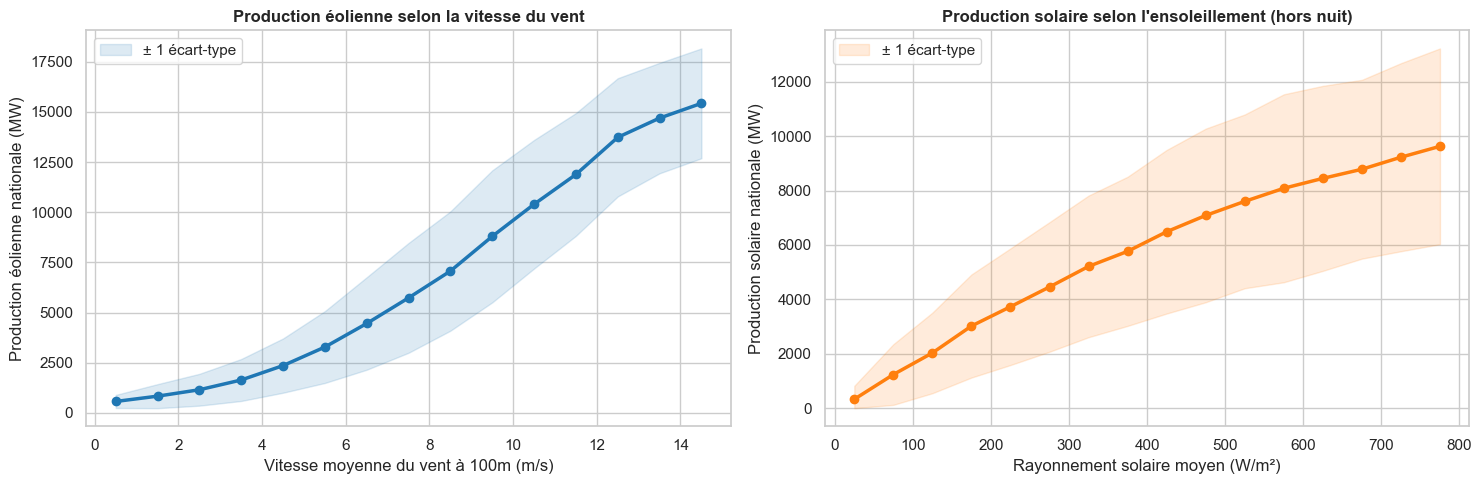

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1A. Vent -> Production Éolienne
df["bin_vent"] = pd.cut(df["wind_speed_100m"], bins=np.arange(0, 16, 1))
vent_profil = df.groupby("bin_vent", observed=True)["eolien"].agg(["mean", "std"]).reset_index()
vent_profil["vent_milieu"] = vent_profil["bin_vent"].apply(lambda x: x.mid).astype(float)

axes[0].plot(vent_profil["vent_milieu"], vent_profil["mean"], marker="o", color="#1f77b4", linewidth=2.5)
axes[0].fill_between(
    vent_profil["vent_milieu"],
    (vent_profil["mean"] - vent_profil["std"]).clip(lower=0),
    vent_profil["mean"] + vent_profil["std"],
    color="#1f77b4", alpha=0.15, label="± 1 écart-type"
)
axes[0].set_title("Production éolienne selon la vitesse du vent", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Vitesse moyenne du vent à 100m (m/s)")
axes[0].set_ylabel("Production éolienne nationale (MW)")
axes[0].legend()

# 1B. Rayonnement -> Production Solaire (hors nuit)
df_jour = df[df["shortwave_radiation"] > 0].copy()
df_jour["bin_rad"] = pd.cut(df_jour["shortwave_radiation"], bins=np.arange(0, 850, 50))
sol_profil = df_jour.groupby("bin_rad", observed=True)["solaire"].agg(["mean", "std"]).reset_index()
sol_profil["rad_milieu"] = sol_profil["bin_rad"].apply(lambda x: x.mid).astype(float)

axes[1].plot(sol_profil["rad_milieu"], sol_profil["mean"], marker="o", color="#ff7f0e", linewidth=2.5)
axes[1].fill_between(
    sol_profil["rad_milieu"],
    (sol_profil["mean"] - sol_profil["std"]).clip(lower=0),
    sol_profil["mean"] + sol_profil["std"],
    color="#ff7f0e", alpha=0.15, label="± 1 écart-type"
)
axes[1].set_title("Production solaire selon l'ensoleillement (hors nuit)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Rayonnement solaire moyen (W/m²)")
axes[1].set_ylabel("Production solaire nationale (MW)")
axes[1].legend()

plt.tight_layout()
plt.show()

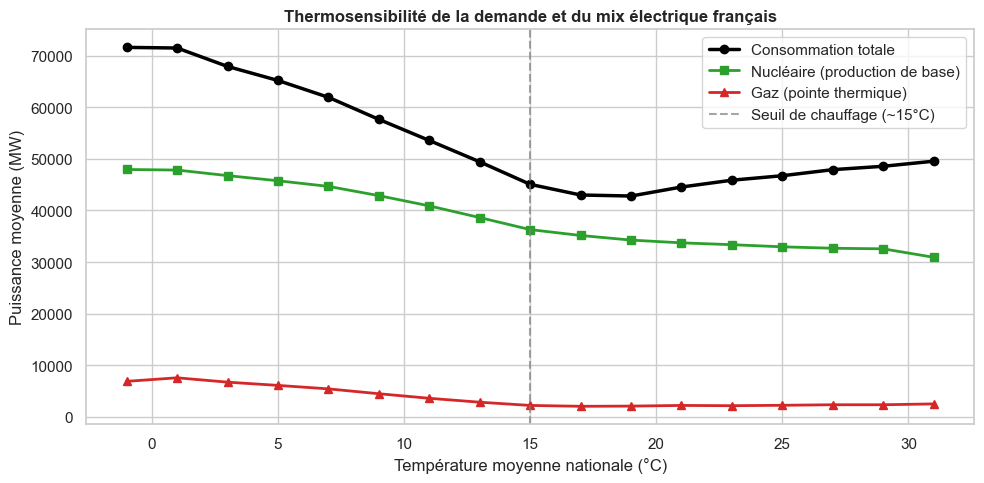

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

df["bin_temp"] = pd.cut(df["temperature_2m"], bins=np.arange(-4, 34, 2))
temp_profil = df.groupby("bin_temp", observed=True)[["consommation", "nucleaire", "gaz"]].mean().reset_index()
temp_profil["temp_milieu"] = temp_profil["bin_temp"].apply(lambda x: x.mid).astype(float)

ax.plot(temp_profil["temp_milieu"], temp_profil["consommation"], marker="o", label="Consommation totale", color="black", linewidth=2.5)
ax.plot(temp_profil["temp_milieu"], temp_profil["nucleaire"], marker="s", label="Nucléaire (production de base)", color="#2ca02c", linewidth=2)
ax.plot(temp_profil["temp_milieu"], temp_profil["gaz"], marker="^", label="Gaz (pointe thermique)", color="#d62728", linewidth=2)
ax.axvline(15, color="gray", linestyle="--", alpha=0.7, label="Seuil de chauffage (~15°C)")

ax.set_title("Thermosensibilité de la demande et du mix électrique français", fontsize=12, fontweight="bold")
ax.set_xlabel("Température moyenne nationale (°C)")
ax.set_ylabel("Puissance moyenne (MW)")
ax.legend()

plt.tight_layout()
plt.show()

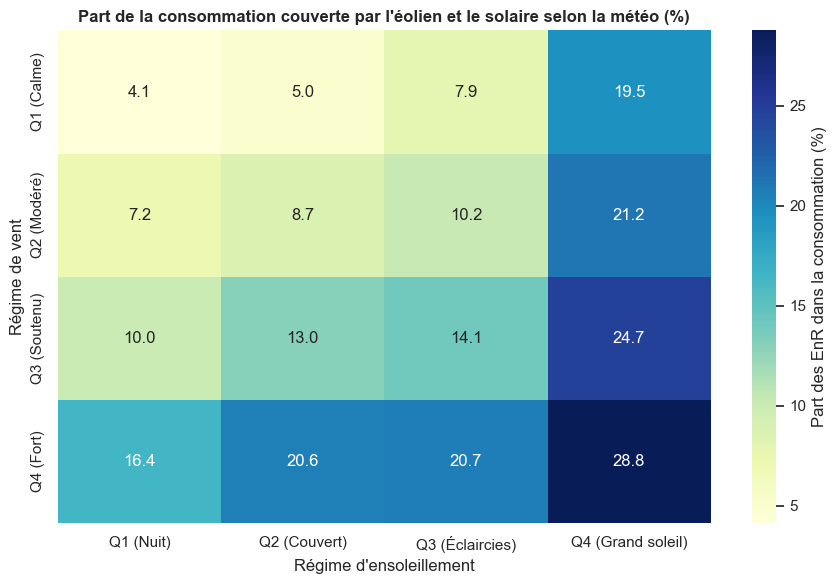

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))

df["q_vent"] = pd.qcut(df["wind_speed_100m"], q=4, labels=["Q1 (Calme)", "Q2 (Modéré)", "Q3 (Soutenu)", "Q4 (Fort)"])
df["q_sol"] = pd.qcut(df["shortwave_radiation"].rank(method="first"), q=4, labels=["Q1 (Nuit)", "Q2 (Couvert)", "Q3 (Éclaircies)", "Q4 (Grand soleil)"])

pivot_enr = df.pivot_table(index="q_vent", columns="q_sol", values="part_enr", aggfunc="mean", observed=False)

sns.heatmap(
    pivot_enr,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    ax=ax,
    cbar_kws={"label": "Part des EnR dans la consommation (%)"}
)
ax.set_title("Part de la consommation couverte par l'éolien et le solaire selon la météo (%)", fontsize=12, fontweight="bold")
ax.set_xlabel("Régime d'ensoleillement")
ax.set_ylabel("Régime de vent")

plt.tight_layout()
plt.show()